# 03 · Correlation Analysis
Module 2.1 (Statistics for Data Science)

**Correlation** measures how strongly two numerical variables move together in a straight-line way.
**Covariance** measures the same direction of movement but in the original units, so its size is hard to compare.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
from src import stats as S

## 1. Load the data
We use the cleaned data (impossible zeros = missing) and the 5 continuous features plus the target `HeartDisease`.
Pearson correlation between a 0/1 variable and a numerical one is called the **point-biserial correlation** and is a
valid way to see how each feature relates to heart disease.

In [2]:
df = data.load_clean()
cols = C.CONTINUOUS + [C.TARGET]
df[cols].head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
0,40,140.000,289.000,172,0.000,0
1,49,160.000,180.000,156,1.000,1
2,37,130.000,283.000,98,0.000,0
3,48,138.000,214.000,108,1.500,1
4,54,150.000,195.000,122,0.000,0


## 2. Karl Pearson's correlation coefficient
$$ r = \frac{\operatorname{cov}(X, Y)}{s_X\, s_Y} = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2}\sqrt{\sum (y_i-\bar y)^2}} $$

* $r = +1$: perfect positive straight-line relationship (both go up together)
* $r = -1$: perfect negative relationship (one goes up, the other goes down)
* $r \approx 0$: no linear relationship

We compute the full matrix with pandas (missing values are skipped pair-wise).

In [3]:
corr = df[cols].corr(method="pearson")
corr.round(3)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
Age,1.000,0.263,0.059,-0.382,0.259,0.282
RestingBP,0.263,1.000,0.096,-0.110,0.174,0.118
Cholesterol,0.059,0.096,1.000,-0.020,0.058,0.104
MaxHR,-0.382,-0.110,-0.020,1.000,-0.161,-0.400
Oldpeak,0.259,0.174,0.058,-0.161,1.000,0.404
HeartDisease,0.282,0.118,0.104,-0.400,0.404,1.000


As a check, we compute one coefficient by hand with our own `pearson_r()` function from `src/stats.py`:

In [4]:
manual = S.pearson_r(df["Age"], df["MaxHR"])
print(f"Manual  r(Age, MaxHR) = {manual:.6f}")
print(f"Pandas  r(Age, MaxHR) = {corr.loc['Age', 'MaxHR']:.6f}")

Manual  r(Age, MaxHR) = -0.382045
Pandas  r(Age, MaxHR) = -0.382045


## 3. Annotated heatmap
Teal = positive correlation, coral = negative, white/grey = close to zero.

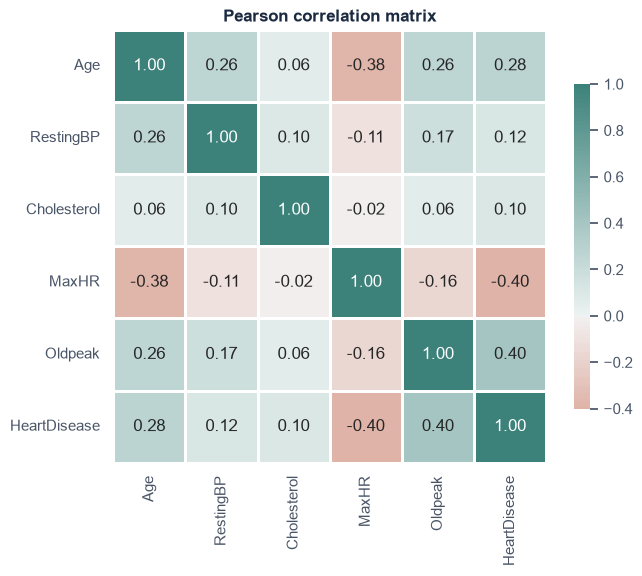

In [5]:
fig = plots.corr_heatmap(corr, "Pearson correlation matrix")
plots.save_fig(fig, "03_correlation_heatmap")
plt.show()

## 4. Covariance matrix
$$ \operatorname{cov}(X, Y) = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{n-1} $$
The **sign** of the covariance tells the direction (same as correlation), but the **size** depends on the units.
For example, Cholesterol is measured in hundreds of mg/dl, so its covariances look huge compared with Oldpeak (a few mm).
That is why we standardise covariance into correlation (dividing by both standard deviations) before comparing.

In [6]:
cov = df[cols].cov()
cov.round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
Age,88.970,44.690,33.040,-91.750,2.600,1.320
RestingBP,44.690,323.990,98.080,-50.280,3.350,1.060
Cholesterol,33.040,98.080,"3,499.140",-28.800,3.710,3.070
MaxHR,-91.750,-50.280,-28.800,648.230,-4.360,-5.070
Oldpeak,2.600,3.350,3.710,-4.360,1.140,0.210
HeartDisease,1.320,1.060,3.070,-5.070,0.210,0.250


Check: dividing a covariance by the two standard deviations gives back the correlation.

In [7]:
c = cov.loc["Age", "MaxHR"] / (df["Age"].std() * df["MaxHR"].std())
print(f"cov(Age, MaxHR) / (s_Age * s_MaxHR) = {c:.4f}   (correlation was {corr.loc['Age', 'MaxHR']:.4f})")

cov(Age, MaxHR) / (s_Age * s_MaxHR) = -0.3820   (correlation was -0.3820)


## 5. Pairplot coloured by heart disease
A **pairplot** shows a scatter plot for every pair of features (and the distribution of each feature on the diagonal).
Colouring by the target shows which feature combinations separate the two classes.

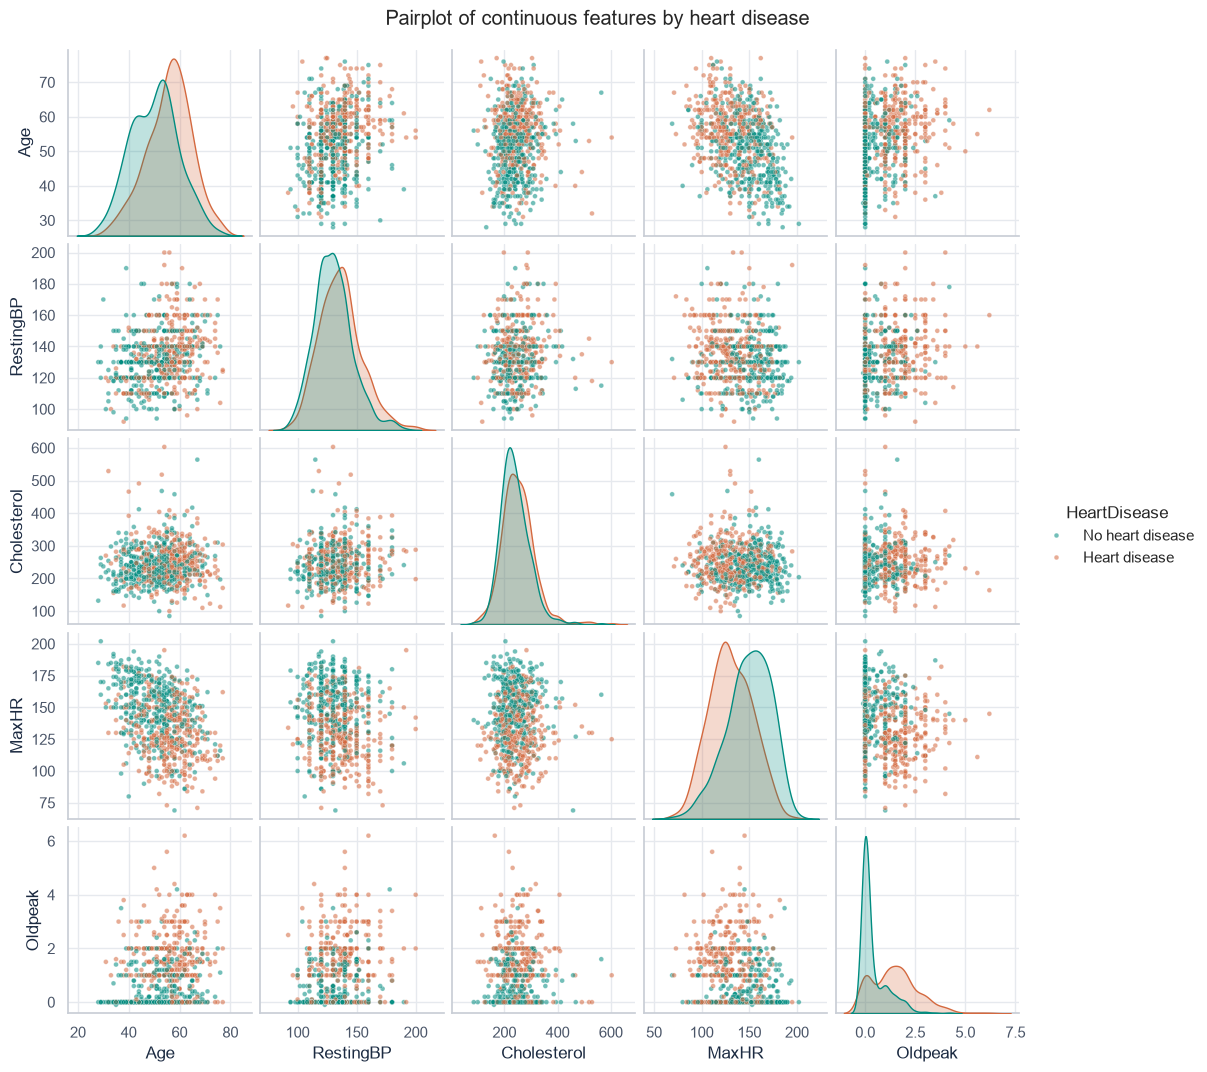

In [8]:
pp = df[cols].dropna().copy()
pp[C.TARGET] = pp[C.TARGET].map(C.CLASS_NAMES)
g = sns.pairplot(pp, hue=C.TARGET, palette={C.CLASS_NAMES[0]: C.CLASS_COLORS[0], C.CLASS_NAMES[1]: C.CLASS_COLORS[1]},
                 plot_kws={"s": 12, "alpha": 0.55, "edgecolor": "white", "linewidth": 0.3},
                 diag_kws={"common_norm": False}, height=2.1)
g.figure.suptitle("Pairplot of continuous features by heart disease", y=1.02)
plots.save_fig(g.figure, "03_pairplot")
plt.show()

## 6. Bubble chart
A **bubble chart** is a scatter plot with a third variable shown as the **size** of each point.
Here: x = Age, y = MaxHR, bubble size = Oldpeak (ST depression), colour = heart disease.
It shows three of the most important features at once: sick patients cluster at **older age, lower MaxHR and bigger bubbles**.

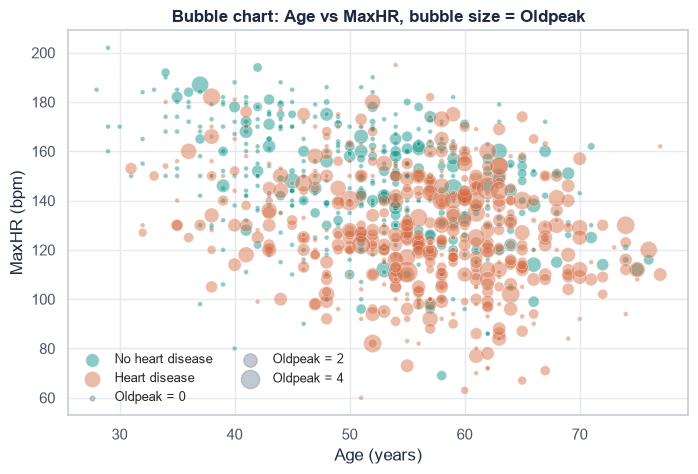

In [9]:
bub = df.dropna(subset=["Age", "MaxHR", "Oldpeak"])
fig, ax = plt.subplots(figsize=(8, 5))
for cls in [0, 1]:
    part = bub[bub[C.TARGET] == cls]
    ax.scatter(part["Age"], part["MaxHR"], s=(part["Oldpeak"].clip(lower=0) + 0.3) * 40,
               color=C.CLASS_COLORS[cls], alpha=0.45, edgecolor="white", linewidth=0.5, label=C.CLASS_NAMES[cls])
for v in [0, 2, 4]:   # size legend
    ax.scatter([], [], s=(v + 0.3) * 40, color="#9AA4B2", alpha=0.6, label=f"Oldpeak = {v}")
ax.set_xlabel("Age (years)")
ax.set_ylabel("MaxHR (bpm)")
ax.set_title("Bubble chart: Age vs MaxHR, bubble size = Oldpeak")
ax.legend(frameon=False, loc="lower left", ncol=2, fontsize=9)
plots.save_fig(fig, "03_bubble_chart")
plt.show()

## 7. Density chart
With 918 overlapping points a scatter plot gets crowded. A **2-D density (KDE contour) chart** draws "height lines" showing
where points are most concentrated - like a map of hills. Each class gets its own contours, so we can see where the
typical healthy and typical sick patient lie.

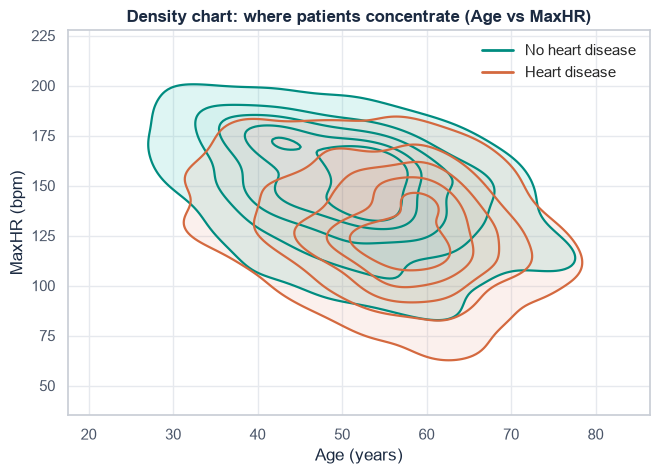

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for cls in [0, 1]:
    part = df[df[C.TARGET] == cls]
    sns.kdeplot(data=part, x="Age", y="MaxHR", ax=ax, color=C.CLASS_COLORS[cls], levels=6, linewidths=1.6)
    sns.kdeplot(data=part, x="Age", y="MaxHR", ax=ax, color=C.CLASS_COLORS[cls], levels=6, fill=True, alpha=0.18)
    ax.plot([], [], color=C.CLASS_COLORS[cls], lw=2, label=C.CLASS_NAMES[cls])
ax.set_title("Density chart: where patients concentrate (Age vs MaxHR)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("MaxHR (bpm)")
ax.legend(frameon=False)
plots.save_fig(fig, "03_density_chart")
plt.show()

## 8. Positive, negative and no correlation - examples from this data
Below we list every pair of features with its coefficient and a description in words, sorted from most positive to most negative.

In [11]:
pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        r = corr.loc[a, b]
        pairs.append({"Feature A": a, "Feature B": b, "r": round(r, 3), "Meaning": S.correlation_strength(r)})
pairs = pd.DataFrame(pairs).sort_values("r", ascending=False).reset_index(drop=True)
pairs

,Feature A,Feature B,r,Meaning
0,Oldpeak,HeartDisease,0.404,moderate positive correlation
1,Age,HeartDisease,0.282,weak positive correlation
2,Age,RestingBP,0.263,weak positive correlation
3,Age,Oldpeak,0.259,weak positive correlation
4,RestingBP,Oldpeak,0.174,weak positive correlation
5,RestingBP,HeartDisease,0.118,weak positive correlation
6,Cholesterol,HeartDisease,0.104,weak positive correlation
7,RestingBP,Cholesterol,0.096,no / negligible correlation
8,Age,Cholesterol,0.059,no / negligible correlation
9,Cholesterol,Oldpeak,0.058,no / negligible correlation


And the correlation of each feature with the target only:

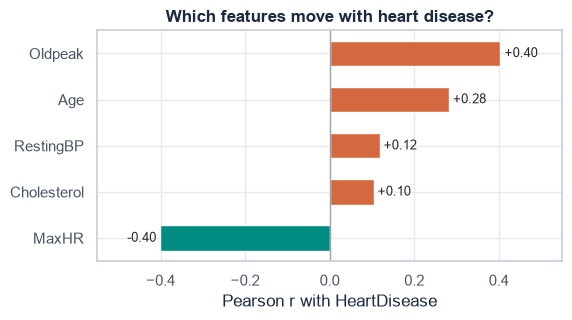

In [12]:
target_corr = corr[C.TARGET].drop(C.TARGET).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(target_corr.index, target_corr.values,
        color=[C.CLASS_COLORS[1] if v > 0 else C.CLASS_COLORS[0] for v in target_corr.values], height=0.55)
ax.axvline(0, color="#9AA4B2", lw=1)
for y, v in enumerate(target_corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-0.55, 0.55)
ax.set_xlabel("Pearson r with HeartDisease")
ax.set_title("Which features move with heart disease?")
plots.save_fig(fig, "03_target_correlation")
plt.show()

### Interpretation
* **Positive correlation** - *Oldpeak* and *HeartDisease*: patients with more ST depression during exercise are more likely
  to have heart disease. *Age* and *RestingBP* also rise together slightly: older patients tend to have higher blood pressure.
* **Negative correlation** - *MaxHR* and *HeartDisease*: patients with heart disease reach a lower maximum heart rate.
  *Age* and *MaxHR* are also negatively correlated: maximum heart rate falls with age (the well-known "220 − age" rule).
* **No (negligible) correlation** - *Cholesterol* and *Oldpeak* (or *Cholesterol* and *MaxHR*) show almost no linear relationship.

### Correlation ≠ causation
A correlation only says that two variables move together **in this sample**. It does **not** prove that one causes the other:
* A low MaxHR does not *cause* heart disease. Both may be caused by a third factor (e.g. age or blocked arteries reduce exercise capacity).
  This is a **confounding variable**.
* Correlation only captures **straight-line** relationships; a strong curved relationship can still give $r \approx 0$.
* Proving causation requires controlled experiments (e.g. randomised clinical trials), not observational data like this.

## Key Findings
* The strongest linear relationships with heart disease are **Oldpeak (r ≈ +0.40)** and **MaxHR (r ≈ −0.40)**, followed by **Age (r ≈ +0.28)**.
* **Cholesterol** (after removing the fake zeros) has only a **weak** correlation with heart disease (≈ +0.10), and **RestingBP** is weak too (≈ +0.12).
* Among the features themselves, **Age vs MaxHR (r ≈ −0.38)** is the strongest relationship; no pair is above |0.5|, so there is **no serious multicollinearity**.
* The **bubble chart** and **2-D density chart** show the healthy group concentrated at younger age / higher MaxHR and the heart-disease group at older age / lower MaxHR with larger Oldpeak.
* Covariance values depend on units (Cholesterol covariances are huge, Oldpeak's are tiny), which is why correlation is used to compare strength.
* These are associations only; they do not prove that any feature causes heart disease.